## EDA Nano


Setup and imports 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
 
# Set some aesthetic preferences for our plots
sns.set_theme(style="whitegrid", palette="viridis")
print("Libraries imported successfully!")

Libraries imported successfully!


Loading and cleaning data 

In [2]:
# Define the column names based on your file format. 
# We only need to name the ones we'll use.
# Note: Python uses 0-based indexing.
column_names = {
    0: 'Index',
    2: 'Displacement_um',
    5: 'PosX_um',
    6: 'PosY_um',
    10: 'Force_uN',
    29: 'Hardness_MPa',
    30: 'ReducedModulus_MPa'
}

# Load the data using pandas.read_csv
# 'comment' tells pandas to ignore lines starting with '//'
# 'delim_whitespace=True' handles the space-separated format
# 'header=None' because there are no column names in the file itself
try:
    df = pd.read_csv('nano.txt', comment='/', delim_whitespace=True, header=None)
    
    # Keep only the columns we need and rename them
    df = df[column_names.keys()].rename(columns=column_names)

    # Convert Index to integer for cleaner grouping
    df['Index'] = df['Index'].astype(int)

    # Remove any rows with NaN (Not a Number) values which can cause errors
    df.dropna(inplace=True)
    
    # Remove initial contact points where force or displacement is negative (often noise)
    df = df[(df['Force_uN'] >= 0) & (df['Displacement_um'] >= 0)]

    print(f"Data loaded successfully!")
    print(f"Found data for {df['Index'].nunique()} unique indentation sites.")
    df.head()

except FileNotFoundError:
    print("Error: nano.txt not found. Please make sure it's in the same directory.")
except Exception as e:
    print(f"An error occurred: {e}")

Data loaded successfully!
Found data for 999 unique indentation sites.


Summary of indents 

In [3]:
# Find the row corresponding to the maximum displacement for each Index
max_disp_indices = df.groupby('Index')['Displacement_um'].idxmax()
summary_df = df.loc[max_disp_indices].set_index('Index')

print("Summary DataFrame created with one entry per indent.")
summary_df.head()

Summary DataFrame created with one entry per indent.


,Displacement_um,PosX_um,PosY_um,Force_uN,Hardness_MPa,ReducedModulus_MPa
Index,,,,,,
1,1.29362,-825.992,5583.945,21472.60572,4307.94055,214503.33691
2,1.34018,-819.922,5583.942,20294.47949,4063.67866,203091.09192
3,1.31793,-813.981,5583.940,20075.96446,4063.24099,201006.23668
4,1.31434,-807.908,5583.942,19638.63072,3967.54683,201317.23541
5,1.33209,-801.939,5583.936,19925.30455,4047.44565,206137.79369


distrubution of mechanical properties

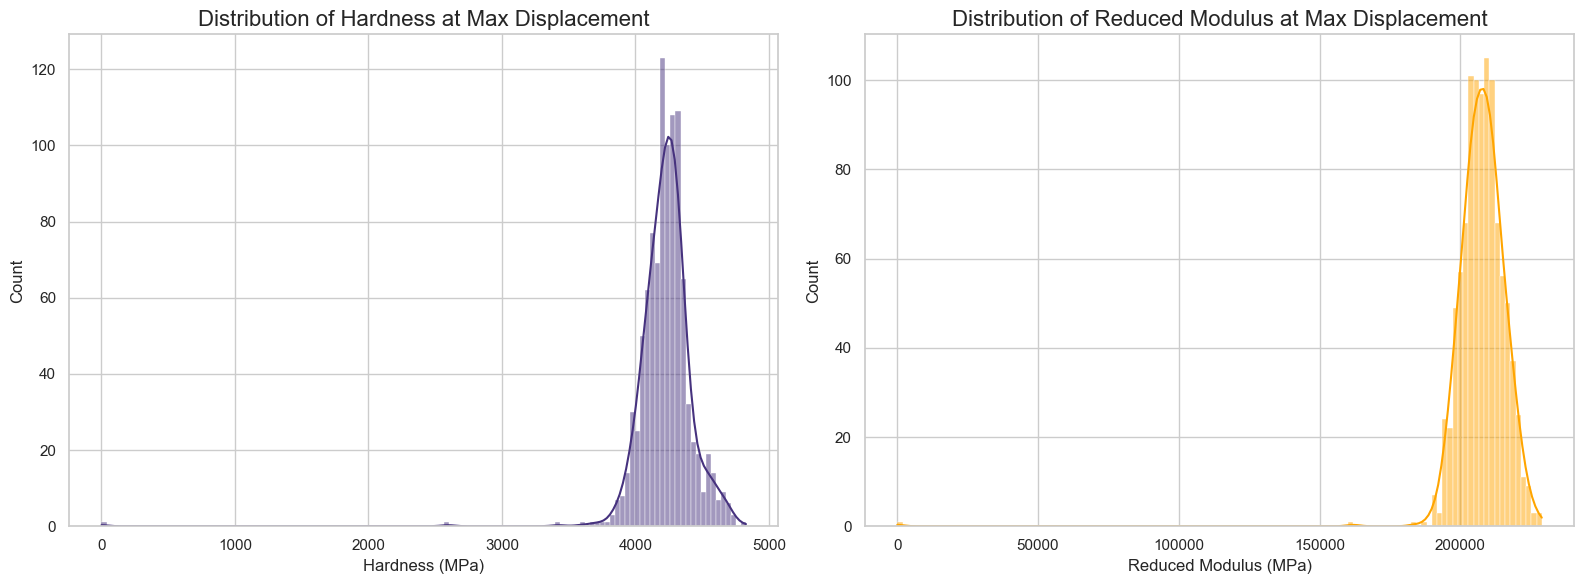

In [4]:
# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Hardness distribution
sns.histplot(data=summary_df, x='Hardness_MPa', kde=True, ax=axes[0])
axes[0].set_title('Distribution of Hardness at Max Displacement', fontsize=16)
axes[0].set_xlabel('Hardness (MPa)', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)

# Plot Reduced Modulus distribution
sns.histplot(data=summary_df, x='ReducedModulus_MPa', kde=True, ax=axes[1], color='orange')
axes[1].set_title('Distribution of Reduced Modulus at Max Displacement', fontsize=16)
axes[1].set_xlabel('Reduced Modulus (MPa)', fontsize=12)

plt.tight_layout()
plt.show()

exploring relationships btw properties 

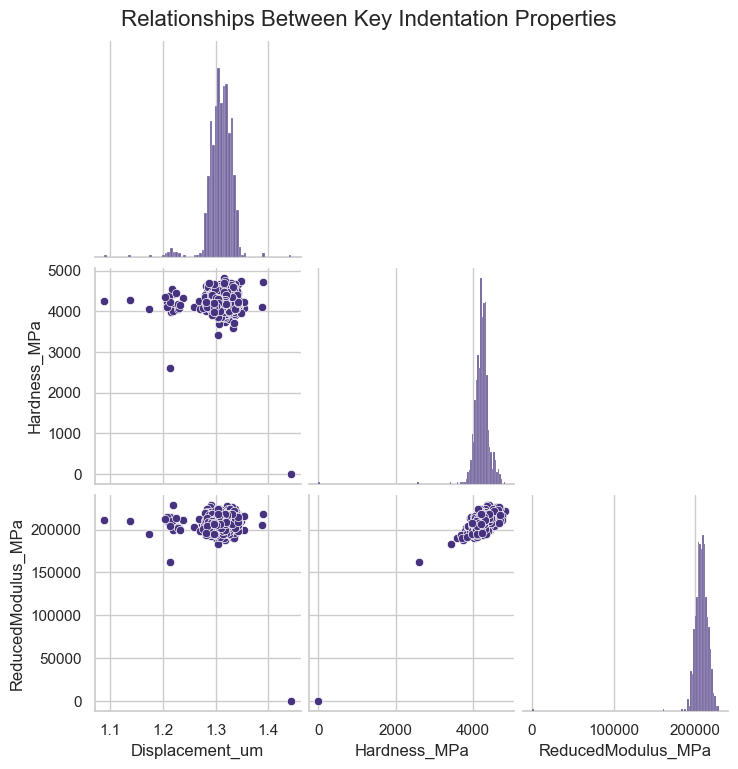

In [5]:
# Select key columns for the pair plot
plot_data = summary_df[['Displacement_um', 'Hardness_MPa', 'ReducedModulus_MPa']]

# Create the pair plot
g = sns.pairplot(plot_data, corner=True)
g.fig.suptitle('Relationships Between Key Indentation Properties', y=1.02, fontsize=16)

plt.show()

sample plots

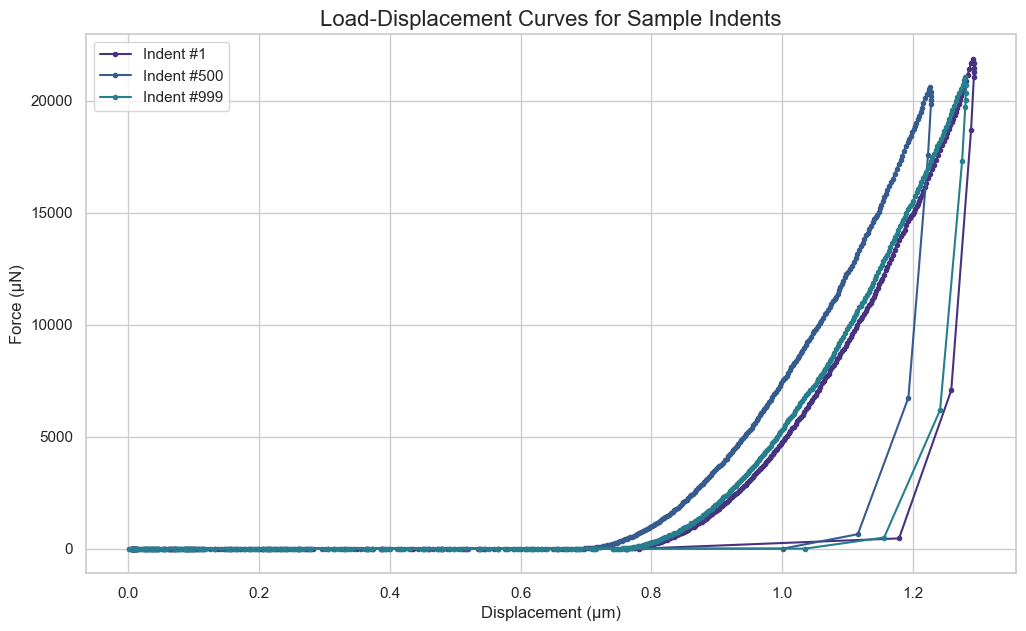

In [6]:
# --- Plotting a few examples ---
sample_indices = [1, 500, 999] # Plot the first, middle, and last indents

plt.figure(figsize=(12, 7))

for index in sample_indices:
    # Get all data for the specific indent
    indent_data = df[df['Index'] == index]
    if not indent_data.empty:
        plt.plot(indent_data['Displacement_um'], indent_data['Force_uN'], marker='.', linestyle='-', label=f'Indent #{index}')

plt.title('Load-Displacement Curves for Sample Indents', fontsize=16)
plt.xlabel('Displacement (μm)', fontsize=12)
plt.ylabel('Force (μN)', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

all 999 plots 

In [7]:
# # Create a directory to store the plots if it doesn't exist
# output_dir = 'indentation_plots'
# if not os.path.exists(output_dir):
#     os.makedirs(output_dir)

# print(f"Preparing to save 999 plots to the '{output_dir}' directory...")

# # Get all unique indent indices
# all_indices = df['Index'].unique()

# # Loop through each index, create a plot, and save it
# for index in all_indices:
#     indent_data = df[df['Index'] == index]
    
#     if not indent_data.empty:
#         fig, ax = plt.subplots(figsize=(8, 6))
#         ax.plot(indent_data['Displacement_um'], indent_data['Force_uN'], color='darkblue')
        
#         ax.set_title(f'Load-Displacement Curve for Indent #{index}', fontsize=14)
#         ax.set_xlabel('Displacement (μm)', fontsize=10)
#         ax.set_ylabel('Force (μN)', fontsize=10)
#         ax.grid(True)
        
#         # Save the figure
#         plt.savefig(os.path.join(output_dir, f'indent_curve_{index}.png'), dpi=100)
        
#         # Close the plot to free up memory
#         plt.close(fig)

# print("Finished! All 999 plots have been saved.")

Box plot

In [8]:
# First, we need to load the combined data we created earlier
try:
    mapped_df = pd.read_csv('mapped_output.txt', delim_whitespace=True)
    
    # Convert Phase to a categorical type for better plotting
    mapped_df['Phase'] = mapped_df['Phase'].astype('category')

    print("Mapped data loaded successfully.")
    
    # Now, let's create the box plot
    plt.figure(figsize=(10, 8))
    
    sns.boxplot(x='Phase', y='Hardness_MPa', data=mapped_df)
    
    plt.title('Comparison of Hardness by Phase', fontsize=16, weight='bold')
    plt.xlabel('EBSD Phase Index', fontsize=12)
    plt.ylabel('Hardness (MPa)', fontsize=12)
    
    # Perform a quick statistical summary
    phase_summary = mapped_df.groupby('Phase')['Hardness_MPa'].describe()
    print("\nStatistical Summary of Hardness per Phase:")
    print(phase_summary)
    
    plt.show()

except FileNotFoundError:
    print("Error: 'mapped_output.txt' not found. Please ensure the mapping script ran successfully.")
except Exception as e:
    print(f"An error occurred: {e}")

Error: 'mapped_output.txt' not found. Please ensure the mapping script ran successfully.


Grain boundary comparison 

In [9]:
# We should already have the mapped_df loaded from the previous cell.
# If not, uncomment the line below.
# mapped_df = pd.read_csv('mapped_output.txt', delim_whitespace=True)

try:
    # Use seaborn's regplot to create a scatter plot with a linear regression line
    plt.figure(figsize=(12, 8))
    
    sns.regplot(x='IQ', y='Hardness_MPa', data=mapped_df,
                scatter_kws={'alpha':0.6, 's':50},  # Make scatter points slightly transparent
                line_kws={'color':'red', 'linestyle':'--'}) # Style the regression line
    
    plt.title('Hardness vs. EBSD Image Quality (IQ)', fontsize=16, weight='bold')
    plt.xlabel('EBSD Image Quality (IQ)', fontsize=12)
    plt.ylabel('Hardness (MPa)', fontsize=12)
    
    # Calculate the Pearson correlation coefficient
    correlation = mapped_df['IQ'].corr(mapped_df['Hardness_MPa'])
    
    # Add the correlation value to the plot
    plt.text(0.05, 0.95, f'Pearson Correlation: {correlation:.3f}',
             transform=plt.gca().transAxes, fontsize=12,
             verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', fc='yellow', alpha=0.5))
    
    plt.show()

except NameError:
    print("Error: The 'mapped_df' DataFrame was not found. Please make sure you ran Cell 8 successfully.")
except Exception as e:
    print(f"An error occurred: {e}")

Error: The 'mapped_df' DataFrame was not found. Please make sure you ran Cell 8 successfully.


<Figure size 1200x800 with 0 Axes>

The investigated area of the material consists of a single phase (Phase 1) which exhibits a uniform and consistent mechanical response. The mean hardness is approximately 4200 MPa. The minor variations in hardness are not correlated with grain boundary effects, suggesting they are due to either inherent experimental scatter or other crystallographic factors

Pop in index identification 

In [12]:
# Assuming the 'df' DataFrame is already loaded and cleaned from the previous cells.
import numpy as np

print("Starting automated pop-in detection algorithm...")

# --- Parameters You Can Adjust ---
# This threshold defines how "flat" the curve must become to be considered a pop-in.
# A smaller number (e.g., 5) makes the detection MORE sensitive (finds smaller events).
# A larger number (e.g., 25) makes it LESS sensitive (finds only very large events).
# A value of 10 is a robust starting point.
SLOPE_THRESHOLD = 10  # Units: uN / um

# This defines the minimum force at which we start looking for pop-ins.
# This is important to ignore noise and the initial contact region at the very beginning of the test.
MIN_FORCE_FOR_DETECTION_uN = 100 


pop_in_indices = []
all_indices = df['Index'].unique()

# --- Loop through each of the 999 indents ---
for index in all_indices:
    indent_data = df[df['Index'] == index]
    
    # Isolate only the loading part of the curve (up to the point of max force)
    if not indent_data.empty:
        # idxmax() finds the first occurrence of the maximum value
        max_force_point_idx = indent_data['Force_uN'].idxmax()
        loading_data = indent_data.loc[:max_force_point_idx]

        # Ensure we have enough points to calculate a slope
        if len(loading_data) < 2:
            continue

        # Calculate the change (delta) in Force and Displacement between each point
        delta_force = loading_data['Force_uN'].diff()
        delta_disp = loading_data['Displacement_um'].diff()

        # Calculate the instantaneous slope (dF/dD)
        # We add a tiny number (epsilon) to avoid the chance of dividing by zero
        epsilon = 1e-9
        slope = delta_force / (delta_disp + epsilon)
        
        # --- The Detection Logic ---
        # We create a boolean mask to find where the conditions for a pop-in are met.
        # Condition 1: The slope is below our threshold.
        # Condition 2: The force is above our minimum detection force (to avoid noise at the start).
        is_pop_in = (slope < SLOPE_THRESHOLD) & (loading_data['Force_uN'] > MIN_FORCE_FOR_DETECTION_uN)
        
        # If any point on the curve meets these conditions...
        if is_pop_in.any():
            # ...we flag this indent index as having a pop-in.
            pop_in_indices.append(index)

# --- Final Report ---
print("\n===========================================")
print("          Pop-in Detection Report          ")
print("===========================================")
if pop_in_indices:
    print(f"Algorithm finished. Found {len(pop_in_indices)} indents with potential pop-in events:")
    # Print the indices in a clean, comma-separated list
    print(", ".join(map(str, sorted(pop_in_indices))))
    print("\nNext step: Manually inspect the saved plots for these specific index numbers to verify.")
else:
    print("Algorithm finished. No significant pop-in events were detected with the current thresholds.")
print("===========================================")

Starting automated pop-in detection algorithm...

          Pop-in Detection Report          
Algorithm finished. Found 21 indents with potential pop-in events:
26, 63, 140, 171, 242, 342, 451, 456, 458, 513, 594, 604, 651, 658, 702, 748, 760, 771, 836, 842, 969

Next step: Manually inspect the saved plots for these specific index numbers to verify.


Generating a 3x7 grid for the 21 detected pop-in events...


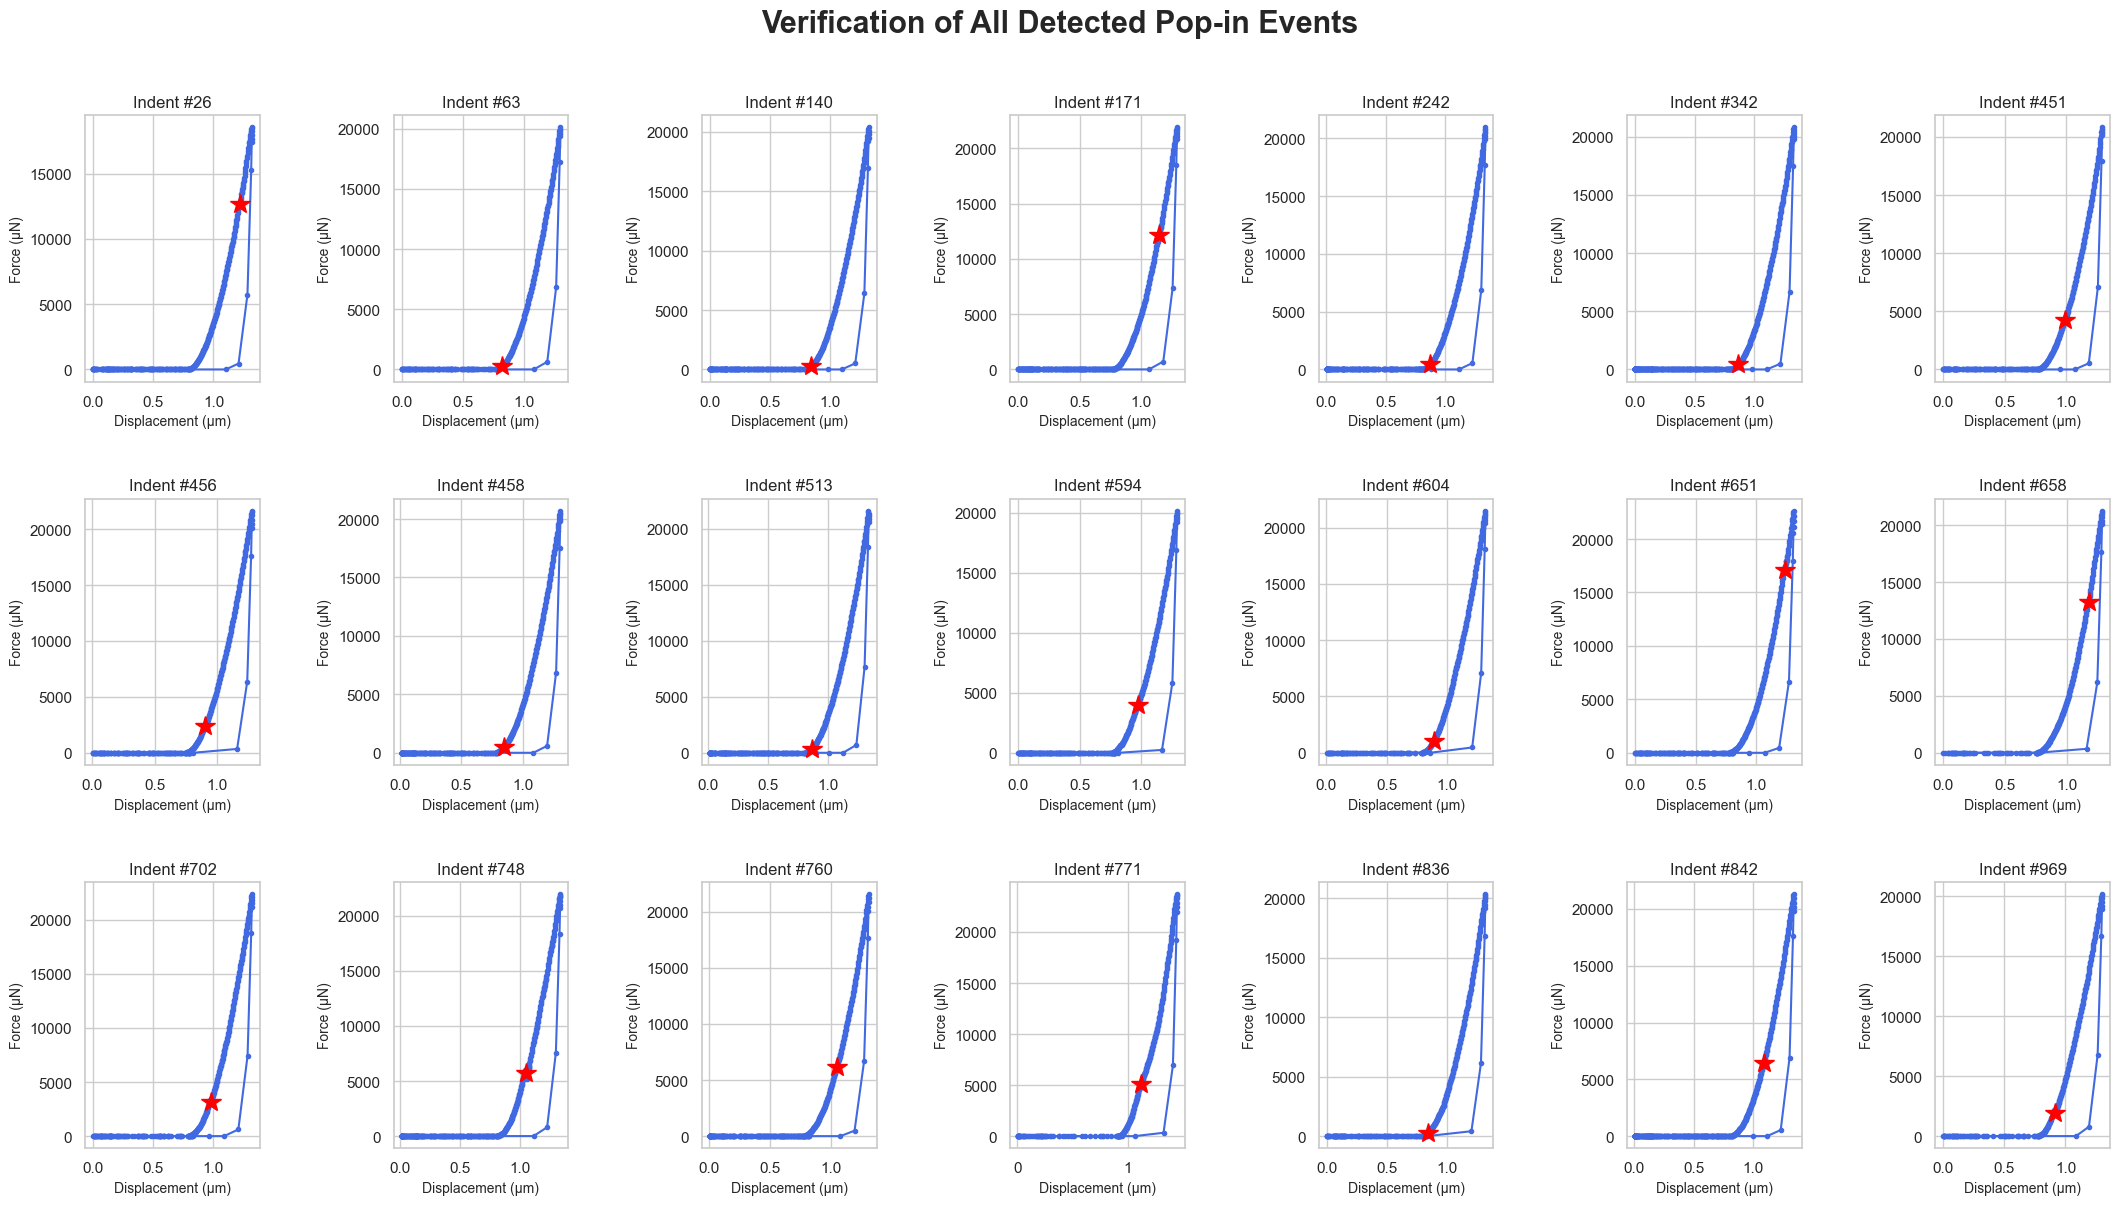

In [13]:
# Assuming the 'df' DataFrame is already loaded and cleaned from previous cells.
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- Your list of identified pop-in indices ---
pop_in_indices = [26, 63, 140, 171, 242, 342, 451, 456, 458, 513, 594, 604, 651, 658, 702, 748, 760, 771, 836, 842, 969]

# --- Use the same detection parameters as before for consistency ---
SLOPE_THRESHOLD = 10
MIN_FORCE_FOR_DETECTION_uN = 100

print(f"Generating a 3x7 grid for the {len(pop_in_indices)} detected pop-in events...")

# --- Create the Grid ---
# We create a figure with 3 rows and 7 columns of subplots.
fig, axes = plt.subplots(3, 7, figsize=(22, 12))

# --- Flatten the Axes Array for easy looping ---
flat_axes = axes.flatten()

# --- Loop Through the Pop-in Indices and Plot on the Grid ---
for i, index in enumerate(pop_in_indices):
    ax = flat_axes[i]  # Select the current subplot
    
    # Get all data for the specific indent
    indent_data = df[df['Index'] == index]
    
    if not indent_data.empty:
        # Plot the full curve
        ax.plot(indent_data['Displacement_um'], indent_data['Force_uN'], marker='.', linestyle='-', color='royalblue', label=f'Indent #{index}')
        
        # --- Highlight the Pop-in Event ---
        # Isolate the loading data to find the pop-in location
        max_force_point_idx = indent_data['Force_uN'].idxmax()
        loading_data = indent_data.loc[:max_force_point_idx]
        
        if len(loading_data) > 2:
            delta_force = loading_data['Force_uN'].diff()
            delta_disp = loading_data['Displacement_um'].diff()
            epsilon = 1e-9
            slope = delta_force / (delta_disp + epsilon)
            
            # Find the first point that meets the pop-in criteria
            pop_in_mask = (slope < SLOPE_THRESHOLD) & (loading_data['Force_uN'] > MIN_FORCE_FOR_DETECTION_uN)
            first_pop_in_point = loading_data[pop_in_mask].first_valid_index()
            
            if first_pop_in_point:
                pop_in_disp = loading_data.loc[first_pop_in_point, 'Displacement_um']
                pop_in_force = loading_data.loc[first_pop_in_point, 'Force_uN']
                # Add a large red star to mark the event
                ax.plot(pop_in_disp, pop_in_force, '*', color='red', markersize=15, label='Pop-in Detected')

        ax.set_title(f'Indent #{index}', fontsize=12)
        ax.set_xlabel('Displacement (μm)', fontsize=10)
        ax.set_ylabel('Force (μN)', fontsize=10)
        ax.grid(True)

# --- Final Touches ---
# This adjusts the spacing between plots.
plt.tight_layout(pad=3.0)

# Add a main title to the entire figure.
fig.suptitle('Verification of All Detected Pop-in Events', fontsize=22, weight='bold', y=1.03)

# Display the entire grid.
plt.show()